# 03 · Coordenação e teste preditivo
Etapas 03.5–03.6. Os testes estão pré-definidos em `docs/plano_de_testes.md` — **não** acrescente especificações depois de ver resultados sem registrar em `docs/decisoes.md`.

In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd, matplotlib.pyplot as plt
from src import config, limpeza
plt.rcParams.update({'figure.figsize': (8, 3.5), 'axes.spines.top': False, 'axes.spines.right': False})
from src import coordenacao as co, preditivo as pr
cl = pd.read_parquet(config.DATA_PROC/'clusters_todos.parquet')
rev = pd.read_csv(config.CLUSTERS_REVISADOS_CSV)
print(len(cl), 'clusters detectados;', len(rev), 'revisados')
cl[['cluster_id','tipo','ticker','n_posts','n_autores','span_min','escore']].head(10)

10 clusters detectados; 10 revisados


,cluster_id,tipo,ticker,n_posts,n_autores,span_min,escore
0,C0001,rajada,BBDC3,3,3,0.0,0.606574
1,C0002,rajada,CMIG4,5,5,0.0,0.597735
2,C0003,rajada,BBAS3,3,3,0.0,0.592224
3,C0004,rajada,BBAS3,12,12,0.0,0.558910
4,C0005,rajada,PETR4,3,3,0.0,0.555780
5,C0006,rajada,PETR4,5,5,0.0,0.547307
6,C0007,rajada,PETR4,4,4,0.0,0.543419
7,C0008,rajada,BBAS3,20,20,0.0,0.539196
8,C0009,rajada,PETR4,10,10,0.0,0.533757
9,C0010,rajada,PETR4,12,12,0.0,0.525728


## Revisão humana dos clusters

In [2]:
print(co.validar_revisao(rev))
co.precisao_no_topo(rev)

[]


{'n': 10,
 'coordenado': 0,
 'provavelmente': 1,
 'organico': 9,
 'precisao_estrita': 0.0,
 'precisao_lata': 0.1}

In [3]:
rev.groupby('decisao_humana')['escore'].describe()[['count','mean','min','max']]

,count,mean,min,max
decisao_humana,,,,
organico,9.0,0.555877,0.525728,0.606574
provavelmente_coordenado,1.0,0.597735,0.597735,0.597735


## Teste preditivo
Execute `python -m src.run_pipeline preditivo` (gera `reports/resultados_preditivo.csv`).

In [4]:
tab = pd.read_csv(config.REPORTS/'resultados_preditivo.csv')
tab[tab.modelo=='controles'][['versao','dv','coef','ep','p','p_holm','n','n_tickers']].round(4)

,versao,dv,coef,ep,p,p_holm,n,n_tickers
1,llm_bruto,ret_excesso_f1,-0.0155,0.0174,0.3741,1.0,31,11
3,llm_bruto,ret_excesso_acum_f1_f5,0.0271,0.0326,0.4063,1.0,12,7
5,llm_bruto,vol_anormal_f1,0.1500,0.1879,0.4249,1.0,29,10
7,llm_bruto,ret_excesso_lag1,-0.0123,0.0051,0.0167,NaN,31,11
9,llm_corrigido,ret_excesso_f1,-0.0076,0.0117,0.5171,1.0,31,11
11,llm_corrigido,ret_excesso_acum_f1_f5,0.0105,0.0323,0.7456,1.0,12,7
13,llm_corrigido,vol_anormal_f1,0.0987,0.2549,0.6987,1.0,29,10
15,llm_corrigido,ret_excesso_lag1,0.0012,0.0059,0.8404,NaN,31,11
17,sem_coordenados,ret_excesso_f1,-0.0079,0.0119,0.5100,1.0,30,11
19,sem_coordenados,ret_excesso_acum_f1_f5,0.0077,0.0395,0.8452,1.0,11,7


## Coeficiente do índice (modelo com controles) — IC 95%

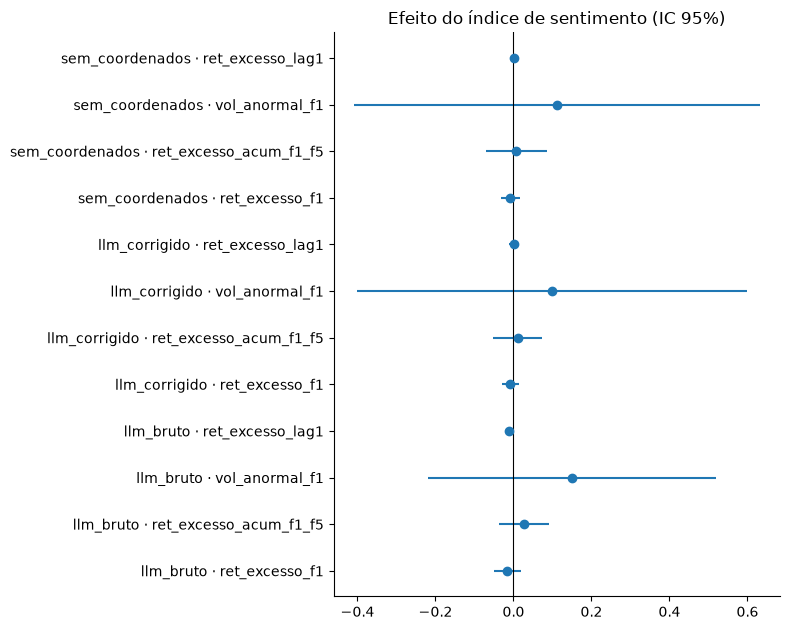

In [5]:
t = tab[(tab.modelo=='controles') & tab.coef.notna()].copy()
t['lbl'] = t['versao'] + ' · ' + t['dv']
plt.figure(figsize=(8, 0.45*len(t)+1))
plt.errorbar(t['coef'], range(len(t)), xerr=1.96*t['ep'], fmt='o')
plt.yticks(range(len(t)), t['lbl']); plt.axvline(0, color='k', lw=.8)
plt.title('Efeito do índice de sentimento (IC 95%)'); plt.tight_layout(); plt.show()

## Leitura honesta
- O placebo (`ret_lag1`) é significativo? Se sim, sinal de causalidade invertida.
- O sinal sobrevive ao controle `ret_t` e à correção de Holm?
- Quantas observações (n) e quantos tickers? Poder estatístico?
- Resultado nulo bem demonstrado é um resultado válido.

In [6]:
pr.conclusao(tab.assign(familia_principal=tab['familia_principal']))

{'ret_excesso_acum_f1_f5': {'todas_versoes_significativas': False,
  'mesmo_sinal': True,
  'n_versoes': 3},
 'ret_excesso_f1': {'todas_versoes_significativas': False,
  'mesmo_sinal': True,
  'n_versoes': 3},
 'vol_anormal_f1': {'todas_versoes_significativas': False,
  'mesmo_sinal': True,
  'n_versoes': 3},
 'ha_sinal': False}